In [1]:
!pip install vaderSentiment gensim -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
warnings.filterwarnings('ignore')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score,
                             precision_score, recall_score)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from gensim import corpora
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'DejaVu Sans'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 39.8 MB/s eta 0:00:00


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [3]:
from google.colab import drive
drive.mount('/content/drive')

BASE_PATH = '/content/drive/MyDrive/datamining/'

Mounted at /content/drive


In [5]:
df = pd.read_csv(BASE_PATH + 'mentalhealth.csv')
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nSample:")
print(df.head())

Shape: (5957, 3)
Columns: ['text', 'title', 'target']

Sample:
                                                text  \
0  Welcome to /r/depression's check-in post - a p...   
1  We understand that most people who reply immed...   
2  Anyone else just miss physical touch? I crave ...   
3  I’m just so ashamed. Everyone and everything f...   
4  I really need a friend. I don't even have a si...   

                                               title  target  
0  Regular check-in post, with information about ...       1  
1  Our most-broken and least-understood rules is ...       1  
2  I haven’t been touched, or even hugged, in so ...       1  
3                    Being Depressed is Embarrassing       1  
4  I'm desperate for a friend and to feel loved b...       1  


In [6]:
print("\nTarget value counts:")
print(df['target'].value_counts().sort_index())

# Map numeric target to risk labels
risk_map = {
    0: 'No Risk',
    1: 'Low Risk',
    2: 'Moderate Risk',
    3: 'High Risk',
    4: 'Very High Risk'
}
df['risk_label'] = df['target'].map(risk_map)

# Use 'text' column as the main text source
TEXT_COL = 'text'

# Drop rows with missing text or very short text
df = df.dropna(subset=[TEXT_COL])
df = df[df[TEXT_COL].astype(str).str.len() > 20].reset_index(drop=True)

print(f"\nDataset after cleaning: {len(df)} rows")
print("\nRisk label distribution:")
print(df['risk_label'].value_counts().sort_index())



Target value counts:
target
0    1181
1    1202
2    1185
3    1201
4    1188
Name: count, dtype: int64

Dataset after cleaning: 5587 rows

Risk label distribution:
risk_label
High Risk         1074
Low Risk          1190
Moderate Risk     1085
No Risk           1097
Very High Risk    1141
Name: count, dtype: int64


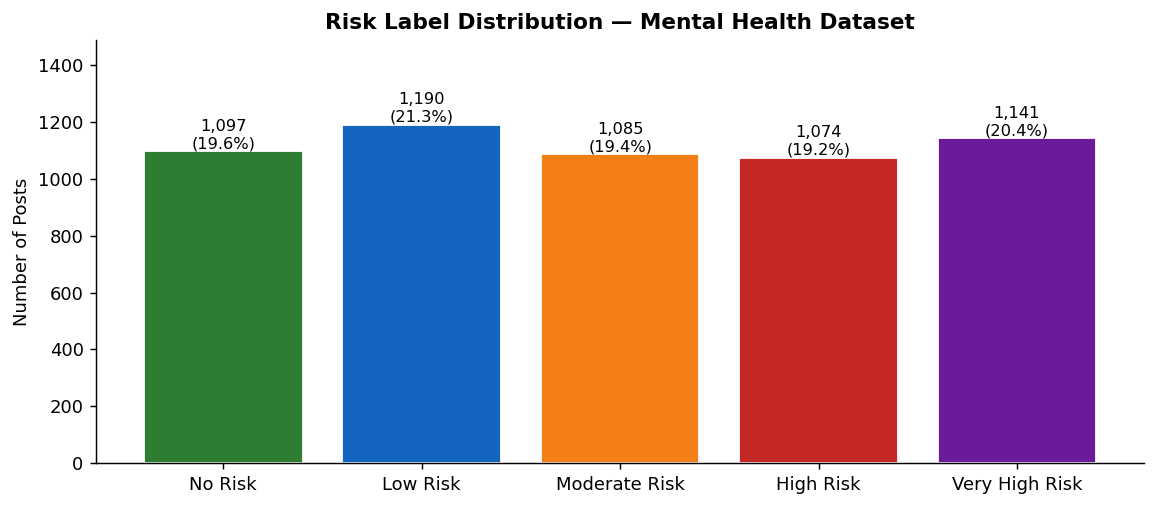

Saved: fig_tm_risk_distribution.png


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
order = ['No Risk', 'Low Risk', 'Moderate Risk', 'High Risk', 'Very High Risk']
counts = df['risk_label'].value_counts().reindex(order)
colors = ['#2E7D32', '#1565C0', '#F57F17', '#C62828', '#6A1B9A']
bars = ax.bar(order, counts.values, color=colors, edgecolor='white')
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 10,
            f'{val:,}\n({val/len(df)*100:.1f}%)',
            ha='center', fontsize=9)
ax.set_title('Risk Label Distribution — Mental Health Dataset',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Posts')
ax.set_ylim(0, counts.max() * 1.25)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(BASE_PATH + 'fig_tm_risk_distribution.png', bbox_inches='tight')
plt.show()
print("Saved: fig_tm_risk_distribution.png")

In [8]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', '', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens
              if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

print("\nPreprocessing text...")
df['clean_text'] = df[TEXT_COL].apply(preprocess)
df = df[df['clean_text'].str.len() > 10].reset_index(drop=True)
print(f"Posts after preprocessing: {len(df)}")



Preprocessing text...
Posts after preprocessing: 5520


In [9]:
analyzer = SentimentIntensityAnalyzer()

def get_vader(text):
    s = analyzer.polarity_scores(str(text))
    return s['compound'], s['pos'], s['neg'], s['neu']

print("\nRunning VADER sentiment analysis...")
df[['compound', 'pos', 'neg', 'neu']] = df[TEXT_COL].apply(
    lambda x: pd.Series(get_vader(x))
)

df['sentiment_label'] = df['compound'].apply(
    lambda c: 'Positive' if c >= 0.05 else ('Negative' if c <= -0.05 else 'Neutral')
)

print("\nSentiment distribution:")
print(df['sentiment_label'].value_counts())
print(f"\nMean Compound Score : {df['compound'].mean():.4f}")
print(f"Mean Positive       : {df['pos'].mean():.4f}")
print(f"Mean Negative       : {df['neg'].mean():.4f}")
print(f"Mean Neutral        : {df['neu'].mean():.4f}")


Running VADER sentiment analysis...

Sentiment distribution:
sentiment_label
Negative    3162
Positive    2194
Neutral      164
Name: count, dtype: int64

Mean Compound Score : -0.1620
Mean Positive       : 0.1116
Mean Negative       : 0.1327
Mean Neutral        : 0.7557


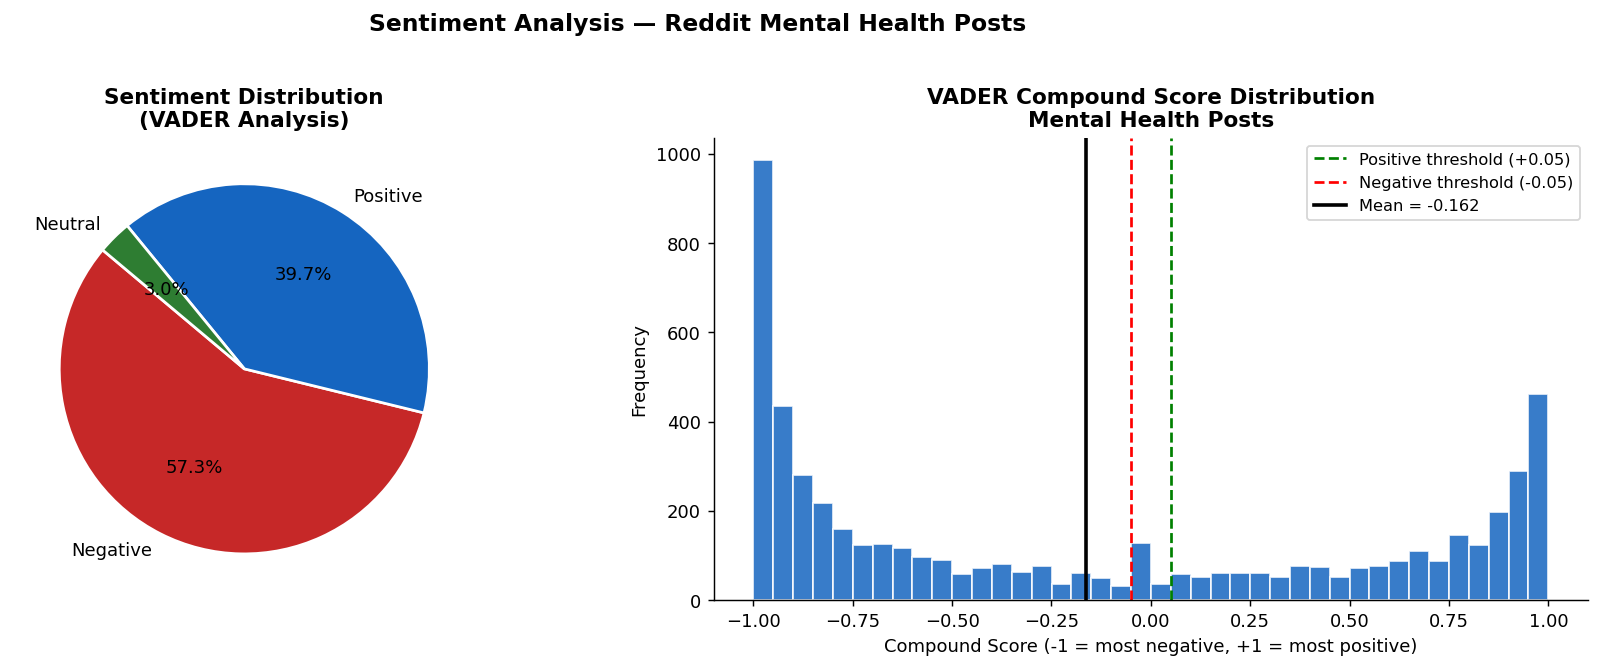

Saved: fig_tm_sentiment.png


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart
sent_counts = df['sentiment_label'].value_counts()
colors_pie = ['#C62828', '#1565C0', '#2E7D32']
axes[0].pie(sent_counts, labels=sent_counts.index,
            autopct='%1.1f%%', colors=colors_pie,
            startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0].set_title('Sentiment Distribution\n(VADER Analysis)',
                  fontsize=12, fontweight='bold')

# Compound score histogram
axes[1].hist(df['compound'], bins=40, color='#1565C0',
             edgecolor='white', alpha=0.85)
axes[1].axvline(0.05, color='green', linestyle='--',
                linewidth=1.5, label='Positive threshold (+0.05)')
axes[1].axvline(-0.05, color='red', linestyle='--',
                linewidth=1.5, label='Negative threshold (-0.05)')
axes[1].axvline(df['compound'].mean(), color='black',
                linestyle='-', linewidth=2,
                label=f'Mean = {df["compound"].mean():.3f}')
axes[1].set_title('VADER Compound Score Distribution\nMental Health Posts',
                  fontsize=12, fontweight='bold')
axes[1].set_xlabel('Compound Score (-1 = most negative, +1 = most positive)')
axes[1].set_ylabel('Frequency')
axes[1].legend(fontsize=9)
axes[1].spines[['top', 'right']].set_visible(False)

plt.suptitle('Sentiment Analysis — Reddit Mental Health Posts',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(BASE_PATH + 'fig_tm_sentiment.png', bbox_inches='tight')
plt.show()
print("Saved: fig_tm_sentiment.png")

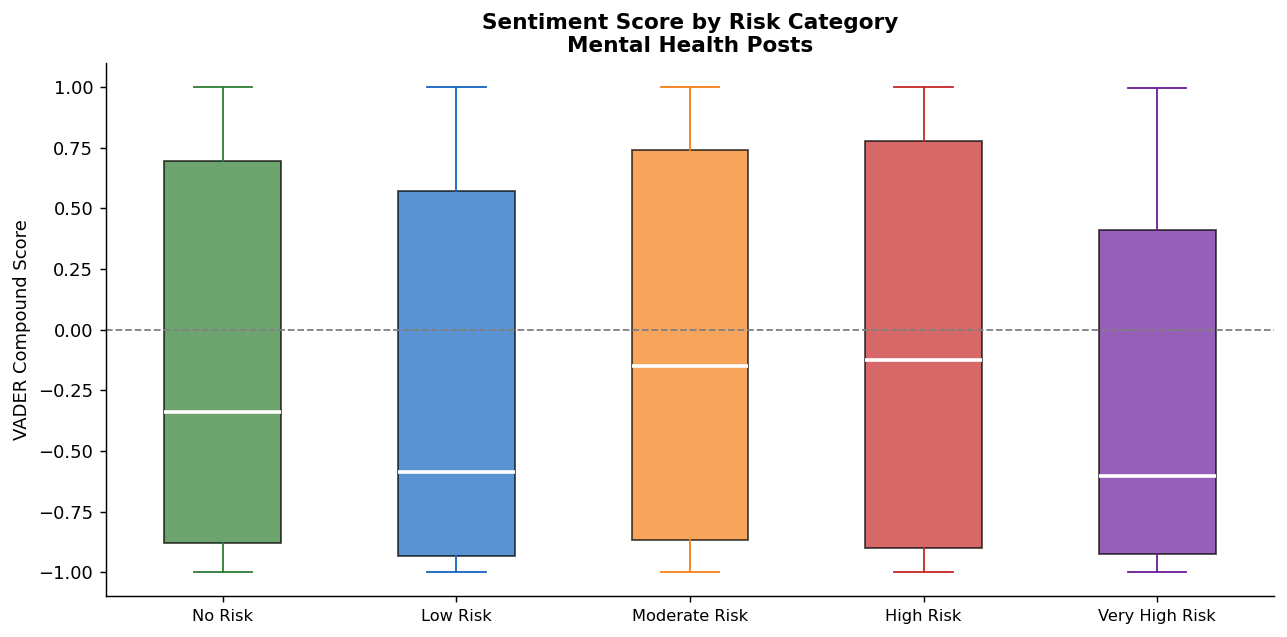

Saved: fig_tm_sentiment_by_risk.png


In [11]:
fig, ax = plt.subplots(figsize=(10, 5))
order = ['No Risk', 'Low Risk', 'Moderate Risk', 'High Risk', 'Very High Risk']
colors_box = ['#2E7D32', '#1565C0', '#F57F17', '#C62828', '#6A1B9A']
for i, (risk, color) in enumerate(zip(order, colors_box)):
    data = df[df['risk_label'] == risk]['compound']
    if len(data) > 0:
        ax.boxplot(data, positions=[i], widths=0.5,
                   patch_artist=True,
                   boxprops=dict(facecolor=color, alpha=0.7),
                   medianprops=dict(color='white', linewidth=2),
                   whiskerprops=dict(color=color),
                   capprops=dict(color=color),
                   flierprops=dict(marker='.', color=color,
                                  alpha=0.3, markersize=3))
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, fontsize=9)
ax.set_ylabel('VADER Compound Score')
ax.set_title('Sentiment Score by Risk Category\nMental Health Posts',
             fontsize=12, fontweight='bold')
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(BASE_PATH + 'fig_tm_sentiment_by_risk.png', bbox_inches='tight')
plt.show()
print("Saved: fig_tm_sentiment_by_risk.png")

In [12]:
print("\nTraining TF-IDF + Logistic Regression classifier...")

X_text = df['clean_text']
y_enc  = df['target'].values

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)
X_tfidf = tfidf.fit_transform(X_text)

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

clf = LogisticRegression(max_iter=1000, class_weight='balanced',
                         random_state=42, C=1.0)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec  = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1   = f1_score(y_test, y_pred, average='macro', zero_division=0)

label_names = ['No Risk', 'Low Risk', 'Moderate Risk', 'High Risk', 'Very High Risk']

print(f"\nTF-IDF + Logistic Regression Results:")
print(f"Accuracy       : {acc:.4f}")
print(f"Macro Precision: {prec:.4f}")
print(f"Macro Recall   : {rec:.4f}")
print(f"Macro F1-Score : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred,
      target_names=label_names, zero_division=0))




Training TF-IDF + Logistic Regression classifier...

TF-IDF + Logistic Regression Results:
Accuracy       : 0.7699
Macro Precision: 0.7778
Macro Recall   : 0.7700
Macro F1-Score : 0.7726

Classification Report:
                precision    recall  f1-score   support

       No Risk       0.81      0.76      0.79       211
      Low Risk       0.67      0.75      0.71       237
 Moderate Risk       0.88      0.78      0.83       217
     High Risk       0.77      0.77      0.77       211
Very High Risk       0.75      0.79      0.77       228

      accuracy                           0.77      1104
     macro avg       0.78      0.77      0.77      1104
  weighted avg       0.78      0.77      0.77      1104



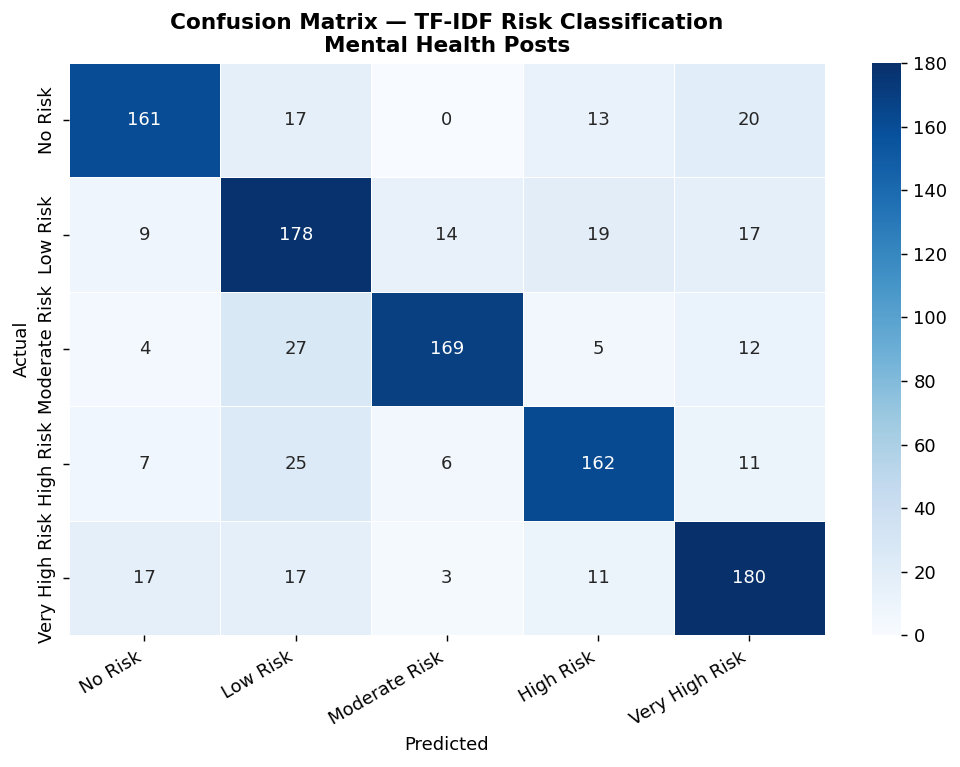

Saved: fig_tm_confusion.png


In [13]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=label_names, yticklabels=label_names,
            linewidths=0.5, linecolor='white')
ax.set_title('Confusion Matrix — TF-IDF Risk Classification\nMental Health Posts',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(BASE_PATH + 'fig_tm_confusion.png', bbox_inches='tight')
plt.show()
print("Saved: fig_tm_confusion.png")

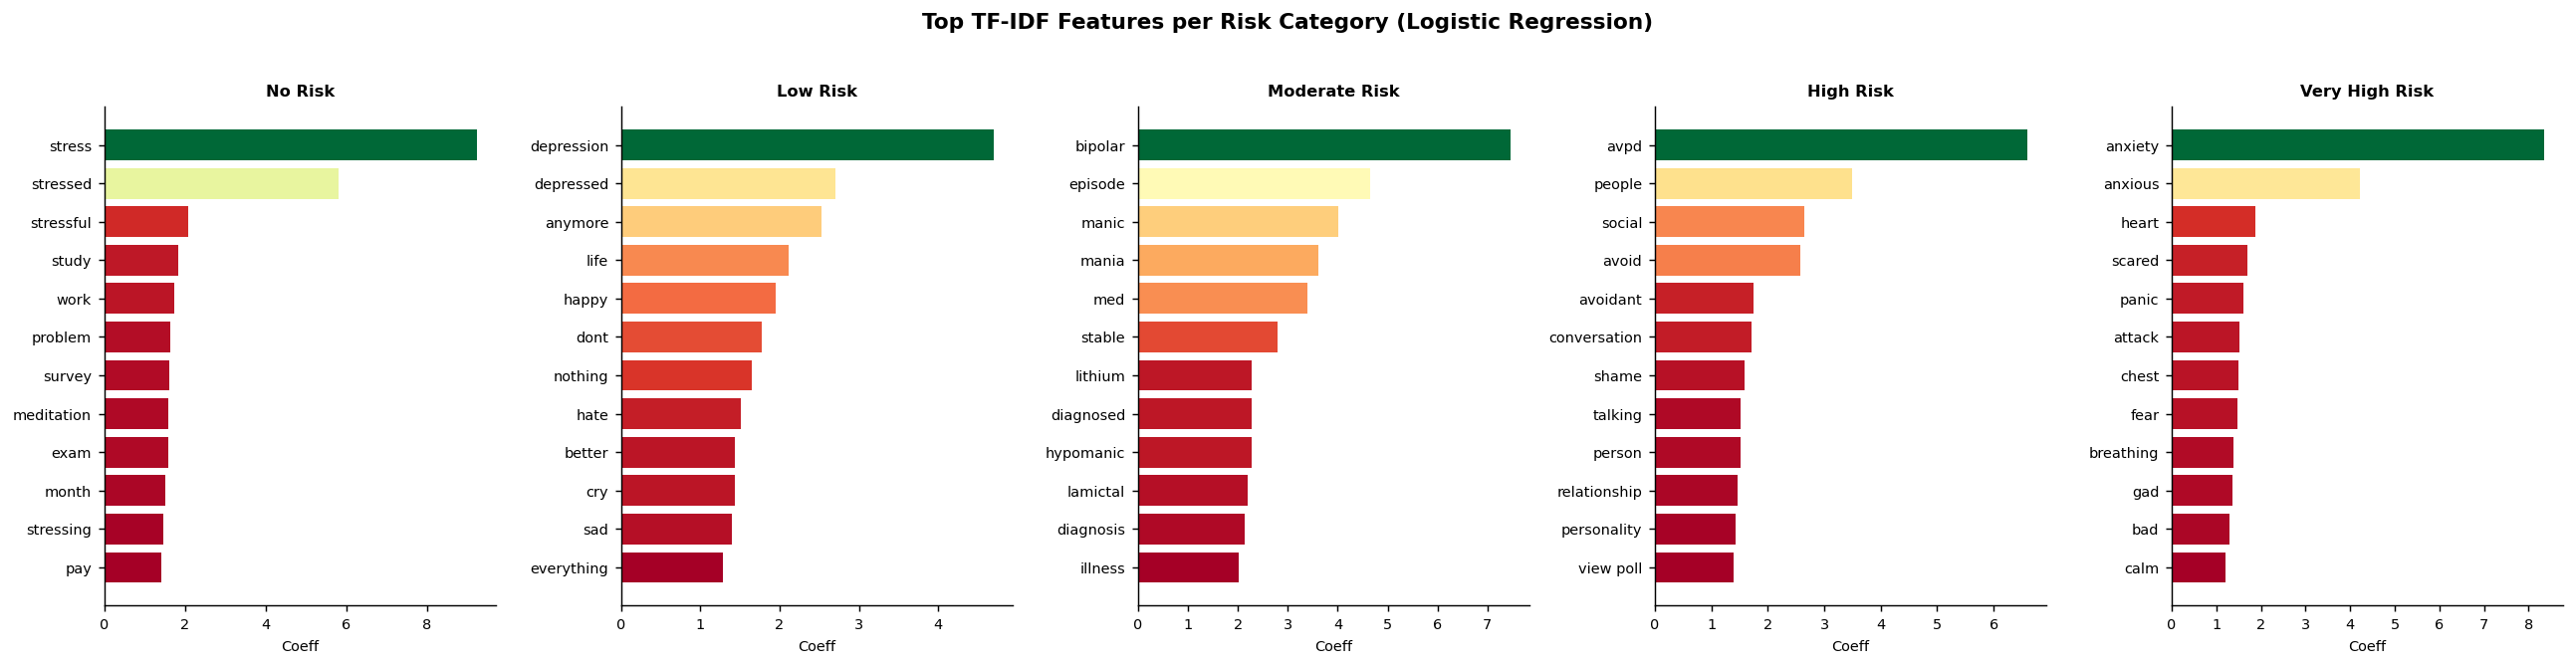

Saved: fig_tm_tfidf_terms.png


In [15]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for i, (ax, class_name) in enumerate(zip(axes, label_names)):
    coef = clf.coef_[i]
    top_idx = np.argsort(coef)[-12:]
    top_words = np.array(tfidf.get_feature_names_out())[top_idx]
    top_coefs = coef[top_idx]

    # ── FIX: ptp() removed in NumPy 2.0 — use np.ptp() instead ──
    coef_range = np.ptp(top_coefs)   # same as max - min
    if coef_range == 0:
        coef_range = 1e-10           # prevent division by zero
    colors_bar = plt.cm.RdYlGn(
        (top_coefs - top_coefs.min()) / coef_range
    )

    ax.barh(top_words, top_coefs, color=colors_bar, edgecolor='none')
    ax.set_title(class_name, fontsize=9, fontweight='bold')
    ax.set_xlabel('Coeff', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle('Top TF-IDF Features per Risk Category (Logistic Regression)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(BASE_PATH + 'fig_tm_tfidf_terms.png', bbox_inches='tight')
plt.show()
print("Saved: fig_tm_tfidf_terms.png")

In [16]:
print("\nRunning LDA topic modeling...")

tokenized = [text.split() for text in df['clean_text'] if len(text.split()) >= 3]

dictionary = corpora.Dictionary(tokenized)
dictionary.filter_extremes(no_below=5, no_above=0.5)
corpus = [dictionary.doc2bow(t) for t in tokenized]

NUM_TOPICS = 5
lda = LdaModel(corpus=corpus, id2word=dictionary,
               num_topics=NUM_TOPICS, random_state=42,
               passes=10, alpha='auto', eta='auto')

print(f"\nLDA Topics ({NUM_TOPICS} topics):")
for i, topic in lda.print_topics(num_words=8):
    print(f"  Topic {i+1}: {topic}")

coherence_model = CoherenceModel(
    model=lda, texts=tokenized,
    dictionary=dictionary, coherence='c_v'
)
coherence = coherence_model.get_coherence()
print(f"\nTopic Coherence Score (C_v): {coherence:.4f}")


Running LDA topic modeling...

LDA Topics (5 topics):
  Topic 1: 0.011*"stress" + 0.011*"anxiety" + 0.009*"time" + 0.009*"help" + 0.006*"thing" + 0.006*"study" + 0.006*"people" + 0.006*"experience"
  Topic 2: 0.010*"time" + 0.010*"year" + 0.010*"one" + 0.009*"would" + 0.008*"day" + 0.008*"life" + 0.008*"didnt" + 0.008*"said"
  Topic 3: 0.017*"ive" + 0.012*"work" + 0.012*"job" + 0.011*"get" + 0.011*"year" + 0.009*"time" + 0.009*"feel" + 0.008*"dont"
  Topic 4: 0.028*"dont" + 0.026*"feel" + 0.018*"people" + 0.016*"know" + 0.015*"want" + 0.013*"even" + 0.011*"get" + 0.011*"life"
  Topic 5: 0.022*"anxiety" + 0.016*"feel" + 0.015*"day" + 0.013*"get" + 0.013*"ive" + 0.009*"feeling" + 0.009*"time" + 0.008*"really"

Topic Coherence Score (C_v): 0.3290


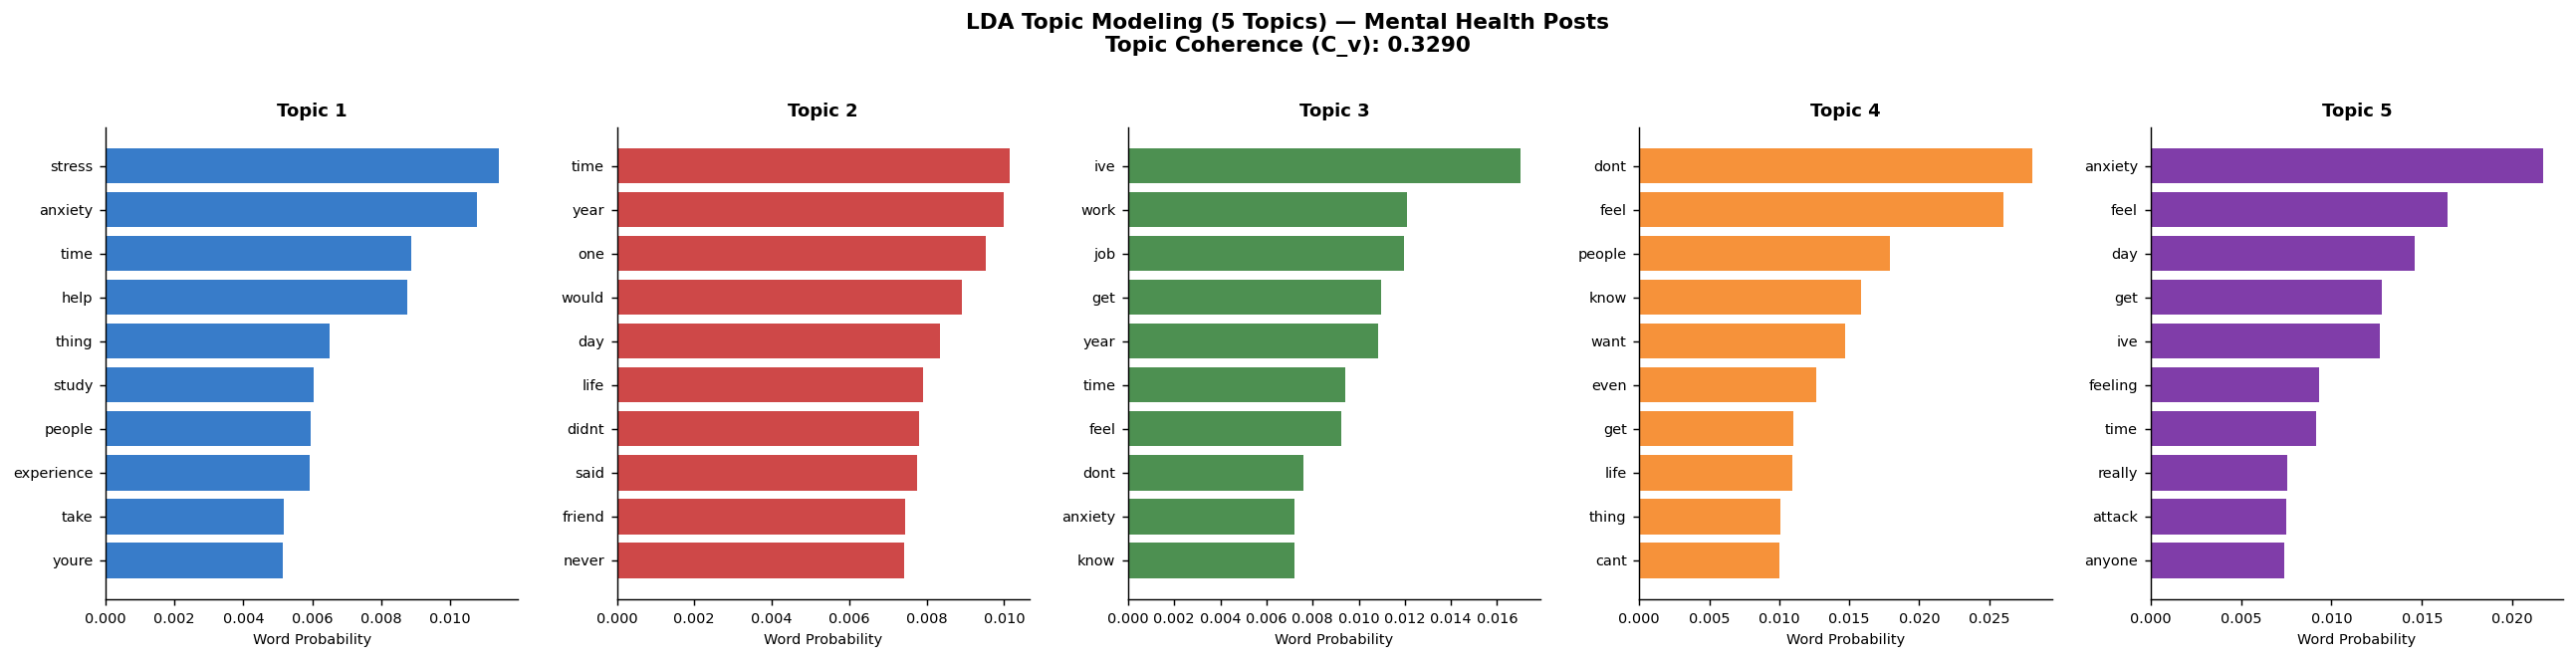

Saved: fig_tm_lda_topics.png


In [17]:
fig, axes = plt.subplots(1, NUM_TOPICS, figsize=(20, 5))
topic_colors = ['#1565C0', '#C62828', '#2E7D32',
                '#F57F17', '#6A1B9A']

for i, ax in enumerate(axes):
    top_words = lda.show_topic(i, topn=10)
    words  = [w for w, _ in top_words][::-1]
    scores = [s for _, s in top_words][::-1]
    ax.barh(words, scores, color=topic_colors[i],
            edgecolor='none', alpha=0.85)
    ax.set_title(f'Topic {i+1}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Word Probability', fontsize=8)
    ax.tick_params(labelsize=8)
    ax.spines[['top', 'right']].set_visible(False)

plt.suptitle(
    f'LDA Topic Modeling ({NUM_TOPICS} Topics) — Mental Health Posts\n'
    f'Topic Coherence (C_v): {coherence:.4f}',
    fontsize=12, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig(BASE_PATH + 'fig_tm_lda_topics.png', bbox_inches='tight')
plt.show()
print("Saved: fig_tm_lda_topics.png")

In [18]:
print("\n" + "=" * 60)
print("FINAL SUMMARY — Text Mining (Mental Health)")
print("=" * 60)
print(f"Total posts analyzed     : {len(df):,}")
print(f"Text column used         : {TEXT_COL}")
print(f"Risk levels              : 0=No Risk, 1=Low, 2=Moderate, 3=High, 4=Very High")
print(f"\nSentiment (VADER):")
print(f"  Negative : {(df['sentiment_label']=='Negative').sum():,} "
      f"({(df['sentiment_label']=='Negative').mean()*100:.1f}%)")
print(f"  Neutral  : {(df['sentiment_label']=='Neutral').sum():,} "
      f"({(df['sentiment_label']=='Neutral').mean()*100:.1f}%)")
print(f"  Positive : {(df['sentiment_label']=='Positive').sum():,} "
      f"({(df['sentiment_label']=='Positive').mean()*100:.1f}%)")
print(f"  Mean Compound Score: {df['compound'].mean():.4f}")
print(f"\nTF-IDF + Logistic Regression:")
print(f"  Accuracy       : {acc:.4f}")
print(f"  Macro Precision: {prec:.4f}")
print(f"  Macro Recall   : {rec:.4f}")
print(f"  Macro F1       : {f1:.4f}")
print(f"\nLDA Topic Modeling:")
print(f"  Number of topics : {NUM_TOPICS}")
print(f"  Coherence (C_v)  : {coherence:.4f}")
print(f"\nAll figures saved to: {BASE_PATH}")


FINAL SUMMARY — Text Mining (Mental Health)
Total posts analyzed     : 5,520
Text column used         : text
Risk levels              : 0=No Risk, 1=Low, 2=Moderate, 3=High, 4=Very High

Sentiment (VADER):
  Negative : 3,162 (57.3%)
  Neutral  : 164 (3.0%)
  Positive : 2,194 (39.7%)
  Mean Compound Score: -0.1620

TF-IDF + Logistic Regression:
  Accuracy       : 0.7699
  Macro Precision: 0.7778
  Macro Recall   : 0.7700
  Macro F1       : 0.7726

LDA Topic Modeling:
  Number of topics : 5
  Coherence (C_v)  : 0.3290

All figures saved to: /content/drive/MyDrive/datamining/
